# B8 – Khai phá dữ liệu: phân cụm sinh viên & luật kết hợp
**Giai đoạn C – Phân tích & Khai phá** · Phương pháp: [`B08_KHAI_PHA_DU_LIEU.md`](../QUY_TRINH_DU_AN/GIAI_DOAN_C_PHAN_TICH_KHAI_PHA/B08_KHAI_PHA_DU_LIEU.md)

Đây là phần **mô tả / khám phá tri thức** (khác với Học máy ở Giai đoạn D là dự báo).
Code: `src/analysis/mining.py` (chạy `python -m src.analysis.mining` để ghi bảng `student_clusters` vào PostgreSQL và xuất `reports/cluster_profiles.csv`, `reports/association_rules.csv`).
Notebook này trình bày quá trình chọn tham số, so sánh thuật toán và diễn giải.

In [1]:
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

from src.analysis.mining import (CLUSTER_FEATURES, ITEM_DEFINITIONS, N_CLUSTERS, describe_clusters,
                                 fit_clusters, make_items, mine_rules, scan_k, student_profile)

sns.set_theme(style="whitegrid", font_scale=0.95)
FIG_DIR = ROOT / "reports" / "figures"
T = "Target_Dropout_Next_Sem"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=110, bbox_inches="tight")

features = pd.read_parquet(ROOT / "data" / "features" / "feature_table.parquet")
profile = student_profile(features)
print(f"Hồ sơ mức sinh viên: {len(profile):,} sinh viên × {len(CLUSTER_FEATURES)} biến phân cụm")
print(f"Tỷ lệ sinh viên cuối cùng bỏ học (mức sinh viên): {profile['Dropped'].mean():.1%}")
profile[CLUSTER_FEATURES].describe().round(2)

Hồ sơ mức sinh viên: 20,000 sinh viên × 8 biến phân cụm
Tỷ lệ sinh viên cuối cùng bỏ học (mức sinh viên): 34.6%


,GPA_mean,Failed_per_sem,Attendance_mean,LMS_mean,Work_mean,Stress_mean,Income_log,Household_Size
count,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00
mean,2.71,0.67,86.07,66.55,17.84,2.84,10.80,3.24
std,0.40,0.54,4.60,8.55,10.45,1.98,0.60,1.34
min,0.96,0.00,69.42,16.00,0.00,1.00,8.01,1.00
25%,2.46,0.33,82.90,61.33,9.40,1.45,10.40,2.00
50%,2.72,0.60,86.00,66.57,17.63,2.23,10.80,3.00
75%,2.98,1.00,89.20,71.75,25.73,3.57,11.20,4.00
max,3.90,5.00,100.00,112.00,40.00,18.10,13.10,6.00


**Cách tổng hợp lên mức sinh viên:** lấy **trung bình theo kỳ** của GPA, số môn trượt, chuyên cần, LMS, giờ làm thêm, áp lực tài chính, cùng thu nhập (log) và quy mô hộ.
Không dùng số kỳ được theo dõi, vì nó phản ánh độ dài quan sát (bỏ học sớm hay dữ liệu bị cắt) chứ không phải đặc điểm của sinh viên.

> **Lưu ý về "tỷ lệ bỏ học" ở notebook này:** tính **theo sinh viên** (sinh viên đó cuối cùng có bỏ học không) = **34,6%**.
> Con số này khác tỷ lệ **10,2%** ở EDA, vốn tính **theo dòng học kỳ** (bỏ học ở *kỳ kế tiếp*).

## 8A.1. Chọn số cụm *k*: Elbow và Silhouette

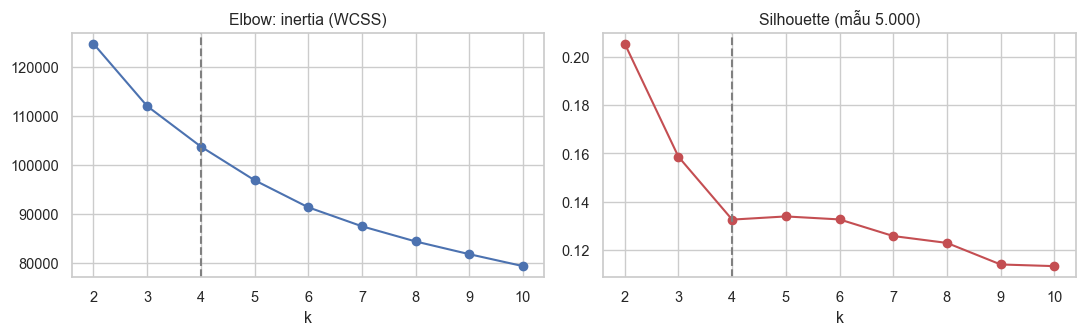

,inertia,silhouette
k,,
2,124785.398,0.205
3,112035.174,0.159
4,103768.067,0.133
5,96893.122,0.134
6,91354.149,0.133
7,87479.205,0.126
8,84374.373,0.123
9,81776.394,0.114
10,79335.142,0.113


In [2]:
scan = scan_k(profile, ks=range(2, 11))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(scan.index, scan["inertia"], marker="o"); axes[0].set_title("Elbow: inertia (WCSS)")
axes[1].plot(scan.index, scan["silhouette"], marker="o", color="#C44E52"); axes[1].set_title("Silhouette (mẫu 5.000)")
for ax in axes:
    ax.set_xlabel("k"); ax.axvline(N_CLUSTERS, color="gray", ls="--")
save(fig, "mining_k_selection.png"); plt.show()
scan.round(3)

**Nhận xét:**
* Đường Elbow **không có khuỷu rõ**: inertia giảm đều. Silhouette cao nhất ở k = 2 (**0,205**), giảm còn **0,13** từ k = 4 trở đi.
* Silhouette dưới 0,25 cho thấy **dữ liệu không chia thành các nhóm tách biệt tự nhiên**: sinh viên phân bố thành một khối liên tục.
* **Chọn k = 4** vì:
  * k = 2 quá thô cho mục tiêu thiết kế chương trình hỗ trợ.
  * Với k = 4, các cụm khác biệt rõ về tỷ lệ bỏ học (mục 8A.2) và diễn giải được.
  * Silhouette của k = 4, 5, 6 gần như bằng nhau (0,133 – 0,134).
* ⇒ Diễn giải 4 cụm như **phân khúc (segmentation)** để hành động, **không** khẳng định đây là 4 "loại sinh viên" tự nhiên.

## 8A.2. Hồ sơ 4 cụm

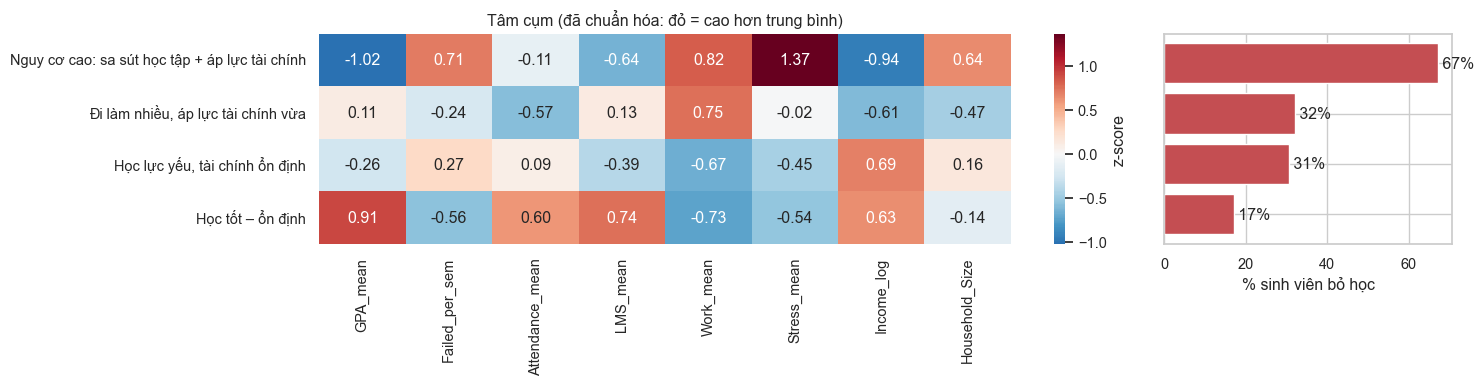

,so_sinh_vien,ty_le_bo_hoc,ty_le_tot_nghiep,the_he_dau,hoc_bong,GPA_mean,Failed_per_sem,Attendance_mean,LMS_mean,Work_mean,Stress_mean,Household_Size,Family_Income_tb,cluster_name
cluster_id,,,,,,,,,,,,,,
2,3881,0.67,0.03,0.34,0.30,2.30,1.06,85.56,61.06,26.44,5.55,4.10,28100.0,Nguy cơ cao: sa sút học tập + áp lực tài chính
0,5566,0.32,0.11,0.35,0.38,2.75,0.55,83.43,67.62,25.70,2.80,2.61,34200.0,"Đi làm nhiều, áp lực tài chính vừa"
3,5360,0.31,0.15,0.37,0.16,2.60,0.82,86.50,63.24,10.81,1.94,3.45,74400.0,"Học lực yếu, tài chính ổn định"
1,5193,0.17,0.09,0.35,0.22,3.07,0.37,88.84,72.91,10.26,1.78,3.05,71800.0,Học tốt – ổn định


In [3]:
labels, km, scaler = fit_clusters(profile)
clusters = describe_clusters(profile, labels)
z = pd.DataFrame(km.cluster_centers_, columns=CLUSTER_FEATURES).loc[clusters.index]
z.index = clusters["cluster_name"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(z, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[0], cbar_kws={"label": "z-score"})
axes[0].set_title("Tâm cụm (đã chuẩn hóa: đỏ = cao hơn trung bình)"); axes[0].set_ylabel("")
axes[1].barh(clusters["cluster_name"], clusters["ty_le_bo_hoc"] * 100, color="#C44E52")
axes[1].invert_yaxis(); axes[1].set_yticklabels([]); axes[1].set_xlabel("% sinh viên bỏ học")
for i, v in enumerate(clusters["ty_le_bo_hoc"] * 100):
    axes[1].text(v, i, f" {v:.0f}%", va="center")
save(fig, "mining_cluster_profiles.png"); plt.show()
clusters.round(2)

**Diễn giải 4 cụm** (sắp xếp theo tỷ lệ bỏ học):

| Cụm | Số SV | Bỏ học | Đặc điểm | Gợi ý can thiệp |
|---|---:|---:|---|---|
| **Nguy cơ cao: sa sút học tập + áp lực tài chính** | 3.881 | **67%** | GPA thấp nhất (2,30), trượt ~1,06 môn/kỳ, làm thêm 26,4 giờ/tuần, áp lực tài chính 5,55, thu nhập thấp (~28.100), hộ đông (4,1 người) | Ưu tiên số 1: hỗ trợ tài chính **và** cố vấn học tập cùng lúc |
| **Đi làm nhiều, áp lực tài chính vừa** | 5.566 | 32% | Làm thêm nhiều (25,7 giờ) nhưng GPA khá (2,75), áp lực vừa (2,80), chuyên cần thấp nhất (83,4%) | Học bổng / việc làm trong trường để giảm giờ làm thêm |
| **Học lực yếu, tài chính ổn định** | 5.360 | 31% | Thu nhập cao (~74.400), ít làm thêm, nhưng GPA 2,60 và trượt 0,82 môn/kỳ | Hỗ trợ **học thuật**: phụ đạo, cố vấn môn học |
| **Học tốt – ổn định** | 5.193 | 17% | GPA 3,07, chuyên cần và LMS cao nhất, ít làm thêm, áp lực thấp | Theo dõi định kỳ, không cần can thiệp |

* Hai cụm giữa có **tỷ lệ bỏ học gần bằng nhau (31 – 32%)** nhưng **nguyên nhân khác nhau** (tài chính và học thuật). Đây là giá trị chính của phân cụm: cùng mức rủi ro nhưng **cách hỗ trợ khác nhau**.
* Tỷ lệ sinh viên thế hệ đầu gần như bằng nhau giữa các cụm (34 – 37%), nên yếu tố này không quyết định cụm.

## 8A.3. Trực quan hóa bằng PCA 2 chiều

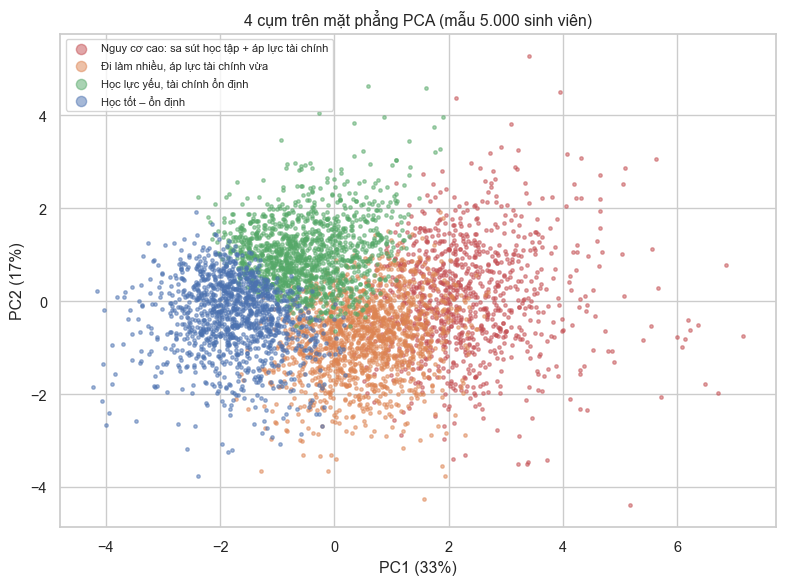

,GPA_mean,Failed_per_sem,Attendance_mean,LMS_mean,Work_mean,Stress_mean,Income_log,Household_Size
PC1,-0.42,0.26,-0.22,-0.29,0.44,0.47,-0.44,0.15
PC2,-0.44,0.49,0.12,-0.49,-0.33,-0.25,0.38,0.02


In [4]:
pca = PCA(2, random_state=42)
X = scaler.transform(profile[CLUSTER_FEATURES])
P = pca.fit_transform(X)
idx = np.random.RandomState(42).choice(len(P), 5000, replace=False)
names = clusters["cluster_name"]
fig, ax = plt.subplots(figsize=(8, 6))
for cid, color in zip(clusters.index, ["#C44E52", "#DD8452", "#55A868", "#4C72B0"]):
    m = labels[idx] == cid
    ax.scatter(P[idx][m, 0], P[idx][m, 1], s=6, alpha=0.5, color=color, label=names[cid])
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=3, fontsize=8); ax.set_title("4 cụm trên mặt phẳng PCA (mẫu 5.000 sinh viên)")
save(fig, "mining_pca.png"); plt.show()
pd.DataFrame(pca.components_, columns=CLUSTER_FEATURES, index=["PC1", "PC2"]).round(2)

**Nhận xét:**
* Hai thành phần chính giữ **49,5%** phương sai (PC1 33%, PC2 17%).
* **PC1 ≈ trục "áp lực tài chính"**: giờ làm thêm (+0,44), áp lực tài chính (+0,47) ngược chiều thu nhập (−0,44) và GPA (−0,42).
* **PC2 ≈ trục "học thuật"**: số môn trượt (+0,49) ngược chiều GPA (−0,44) và LMS (−0,49).
* Các cụm nằm **liền nhau trong một đám mây**, không có ranh giới rõ, đúng như silhouette thấp gợi ý.

## 8A.4. So sánh với DBSCAN

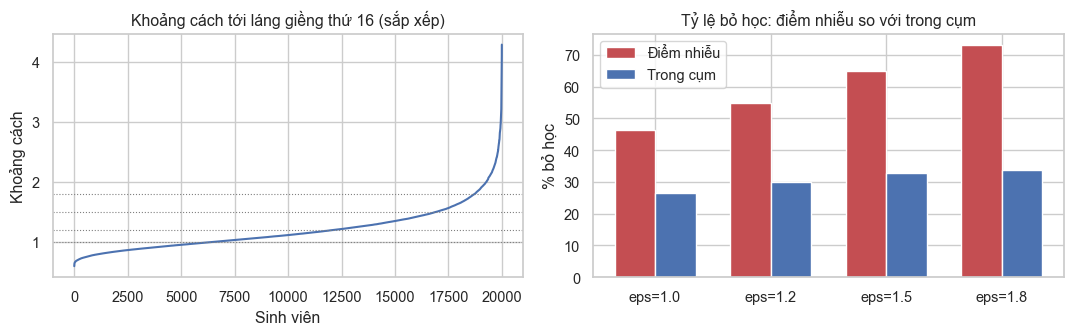

,so_cum,nhieu_%,bo_hoc_nhieu_%,bo_hoc_trong_cum_%
eps,,,,
1.0,1,40.7,46.4,26.5
1.2,1,17.9,55.0,30.1
1.5,1,5.3,64.9,32.9
1.8,1,1.9,73.1,33.8


In [5]:
k_dist = np.sort(NearestNeighbors(n_neighbors=16).fit(X).kneighbors(X)[0][:, -1])
rows = []
for eps in (1.0, 1.2, 1.5, 1.8):
    lab = DBSCAN(eps=eps, min_samples=16).fit_predict(X)
    noise = lab == -1
    rows.append({"eps": eps, "so_cum": len(set(lab[~noise])), "nhieu_%": round(noise.mean() * 100, 1),
                 "bo_hoc_nhieu_%": round(profile["Dropped"][noise].mean() * 100, 1),
                 "bo_hoc_trong_cum_%": round(profile["Dropped"][~noise].mean() * 100, 1)})
dbscan = pd.DataFrame(rows).set_index("eps")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_dist); axes[0].set_title("Khoảng cách tới láng giềng thứ 16 (sắp xếp)")
axes[0].set_xlabel("Sinh viên"); axes[0].set_ylabel("Khoảng cách")
for e in dbscan.index:
    axes[0].axhline(e, color="gray", ls=":", lw=0.8)
w = 0.35
axes[1].bar(np.arange(len(dbscan)) - w / 2, dbscan["bo_hoc_nhieu_%"], w, color="#C44E52", label="Điểm nhiễu")
axes[1].bar(np.arange(len(dbscan)) + w / 2, dbscan["bo_hoc_trong_cum_%"], w, color="#4C72B0", label="Trong cụm")
axes[1].set_xticks(range(len(dbscan)), [f"eps={e}" for e in dbscan.index]); axes[1].set_ylabel("% bỏ học")
axes[1].legend(); axes[1].set_title("Tỷ lệ bỏ học: điểm nhiễu so với trong cụm")
save(fig, "mining_dbscan.png"); plt.show()
dbscan

**Nhận xét:**
* Với mọi `eps` thử (`min_samples = 16 = 2 × số chiều`), DBSCAN chỉ tìm thấy **1 cụm dày đặc** + các điểm nhiễu. Điều này xác nhận dữ liệu là **một khối liên tục**, không có nhóm tách biệt về mật độ.
* **Điểm nhiễu** (sinh viên có hồ sơ khác thường) có tỷ lệ bỏ học **cao vượt trội**: eps = 1,5 → nhiễu 5,3% số sinh viên với **65%** bỏ học, so với 33% trong cụm; eps = 1,8 → 73%.
* ⇒ K-Means và DBSCAN bổ sung cho nhau:
  * **K-Means:** chia phân khúc để thiết kế chương trình hỗ trợ.
  * **DBSCAN:** **phát hiện sinh viên bất thường**, là nhóm nên rà soát thủ công.

## 8B.1. Rời rạc hóa thành item

In [6]:
labeled = features[features["Censored"] == 0]
items = make_items(labeled)
support = pd.DataFrame({"dinh_nghia": pd.Series(ITEM_DEFINITIONS), "support": items.mean().round(3),
                        "ty_le_bo_hoc_khi_co_item_%": [round(labeled.loc[items[c], T].mean() * 100, 1) for c in items]})
print(f"{len(items):,} giao dịch (dòng có nhãn) × {items.shape[1]} item")
support

68,124 giao dịch (dòng có nhãn) × 11 item


,dinh_nghia,support,ty_le_bo_hoc_khi_co_item_%
GPA_Low,"Sem_GPA < 2,0 (diện cảnh báo học vụ)",0.055,40.2
Failed_2plus,Failed_Courses ≥ 2 trong kỳ,0.139,25.4
Attendance_Low,Attendance < 75%,0.038,18.9
Stress_High,Financial_Stress ≥ 5,0.102,26.2
Work_High,Work_Hours ≥ 25 giờ/tuần,0.252,16.0
GPA_Drop,"Delta_GPA ≤ −0,3 so với kỳ trước",0.080,25.7
First_Gen,Sinh viên thế hệ đầu,0.330,13.6
No_Scholarship,Không có học bổng,0.725,11.2
Has_Emergency,Có chi phí khẩn cấp trong kỳ,0.080,10.2
LMS_Low,LMS_Logins dưới phân vị 25,0.243,14.1


## 8B.2. Apriori và FP-Growth

In [7]:
t0 = time.perf_counter(); fi_apriori = apriori(items, min_support=0.01, use_colnames=True); t_apriori = time.perf_counter() - t0
t0 = time.perf_counter(); fi_fp = fpgrowth(items, min_support=0.01, use_colnames=True); t_fp = time.perf_counter() - t0
same = set(map(frozenset, fi_apriori["itemsets"])) == set(map(frozenset, fi_fp["itemsets"]))
print(f"Apriori: {len(fi_apriori)} itemset phổ biến trong {t_apriori:.2f} s")
print(f"FP-Growth: {len(fi_fp)} itemset phổ biến trong {t_fp:.2f} s | cùng kết quả: {same}")

Apriori: 129 itemset phổ biến trong 0.07 s
FP-Growth: 129 itemset phổ biến trong 18.08 s | cùng kết quả: True


**Nhận xét:**
* Hai thuật toán cho **cùng tập itemset phổ biến**, đúng như lý thuyết.
* Ở đây **Apriori nhanh hơn**: chỉ có 11 item, nên số ứng viên nhỏ và cách cắt tỉa của Apriori rất hiệu quả. Cài đặt Apriori của `mlxtend` được vector hóa bằng NumPy, còn FP-Growth dựng cây bằng Python thuần.
* Lợi thế của FP-Growth (không sinh ứng viên, chỉ quét dữ liệu 2 lần) chỉ thể hiện khi **số item lớn**, ví dụ giỏ hàng hàng nghìn sản phẩm. ⇒ Chọn thuật toán phải dựa vào **hình dạng dữ liệu**, không chỉ độ phức tạp lý thuyết.

## 8B.3. Luật dẫn tới bỏ học

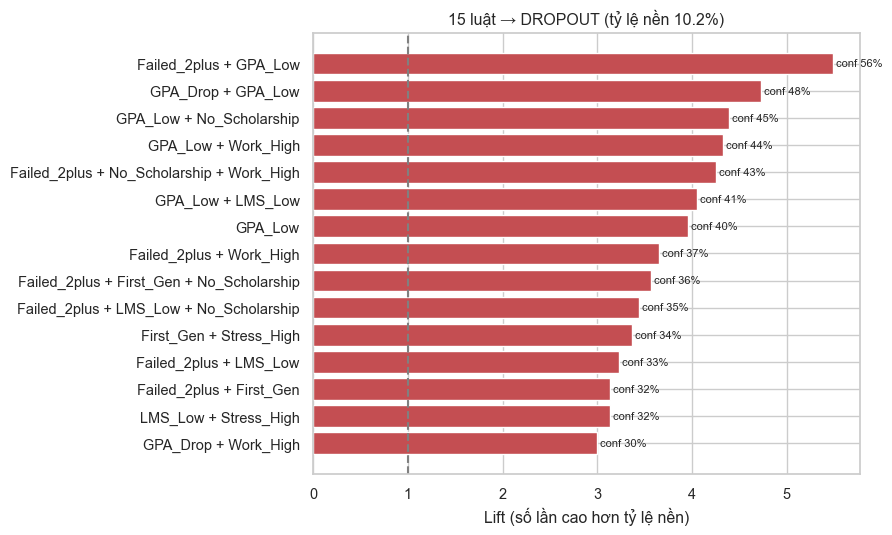

,antecedents,so_item,so_dong,support,confidence,lift
0,Failed_2plus + GPA_Low,2,784,0.012,0.558,5.492
1,GPA_Drop + GPA_Low,2,737,0.011,0.480,4.723
2,GPA_Low + No_Scholarship,2,1085,0.016,0.445,4.387
3,GPA_Low + Work_High,2,908,0.013,0.439,4.324
4,Failed_2plus + No_Scholarship + Work_High,3,759,0.011,0.432,4.255
5,GPA_Low + LMS_Low,2,808,0.012,0.412,4.054
6,GPA_Low,1,1501,0.022,0.402,3.958
7,Failed_2plus + Work_High,2,1068,0.016,0.370,3.647
8,Failed_2plus + First_Gen + No_Scholarship,3,690,0.010,0.362,3.562
9,Failed_2plus + LMS_Low + No_Scholarship,3,735,0.011,0.349,3.441


In [8]:
rules = mine_rules(items)
base = labeled[T].mean()
fig, ax = plt.subplots(figsize=(9, 5.5))
r = rules.iloc[::-1]
ax.barh(r["antecedents"], r["lift"], color="#C44E52")
for i, (lift, conf) in enumerate(zip(r["lift"], r["confidence"])):
    ax.text(lift, i, f" conf {conf:.0%}", va="center", fontsize=8)
ax.axvline(1, color="gray", ls="--"); ax.set_xlabel("Lift (số lần cao hơn tỷ lệ nền)")
ax.set_title(f"{len(rules)} luật → DROPOUT (tỷ lệ nền {base:.1%})")
save(fig, "mining_rules.png"); plt.show()
rules.round(3)

**Diễn giải** (tỷ lệ bỏ học nền 10,2%):
* **Mạnh nhất:** `{GPA thấp + trượt ≥ 2 môn}` → **55,8%** bỏ học (lift **5,5**). `{GPA thấp + GPA tụt ≥ 0,3}` → 48,0% (lift 4,7), xác nhận giá trị của `Delta_GPA` ở B7.
* **GPA < 2,0 là "item trung tâm":** một mình đã cho 40,2%. Kết hợp với *không học bổng*, *làm thêm ≥ 25 giờ* hay *ít đăng nhập LMS* đều lên 41 – 45%.
* **Tài chính + học tập:** `{trượt ≥ 2 + không học bổng + làm thêm nhiều}` → 43,2%; `{thế hệ đầu + áp lực tài chính cao}` → 34,2%.
* **Không xuất hiện** trong luật nào: `Attendance_Low`, `Has_Emergency`, khớp với tín hiệu yếu ở B6 / B7.

**Đề xuất chính sách từ luật:**

| Luật | Can thiệp gợi ý |
|---|---|
| GPA < 2,0 + trượt ≥ 2 môn | Cảnh báo học vụ sớm, cố vấn học tập bắt buộc |
| GPA tụt mạnh so với kỳ trước | Liên hệ ngay khi điểm giữa kỳ giảm, không chờ cuối kỳ |
| Trượt môn + không học bổng + làm thêm nhiều | Học bổng khó khăn / việc làm trong trường để giảm giờ làm thêm |
| Thế hệ đầu + áp lực tài chính cao | Chương trình đồng hành cho sinh viên thế hệ đầu, tư vấn tài chính |

## Tổng kết B8

| | Phát hiện | Ý nghĩa |
|---|---|---|
| K-Means (k = 4) | 4 phân khúc với tỷ lệ bỏ học 67% / 32% / 31% / 17%; hai cụm giữa cùng rủi ro nhưng khác nguyên nhân (tài chính và học thuật) | Thiết kế chương trình hỗ trợ theo phân khúc; bảng `student_clusters` cho dashboard |
| Silhouette ≈ 0,13, DBSCAN 1 cụm | Không có nhóm tự nhiên tách biệt | Diễn giải cụm là phân khúc, không phải "loại" sinh viên |
| DBSCAN – điểm nhiễu | 5,3% sinh viên bất thường, 65% bỏ học | Danh sách rà soát thủ công |
| Apriori | 15 luật lift ≥ 2; mạnh nhất GPA thấp + trượt ≥ 2 môn (55,8%, lift 5,5) | Quy tắc cảnh báo dễ hiểu, bổ sung cho mô hình ML |

Cụm **không** dùng làm đặc trưng cho mô hình (K-Means fit trên toàn bộ sinh viên, nếu dùng sẽ rò rỉ thông tin của tập Test).